# Universe Selection
- Using all symbols ohlcv1d and volume information
- Based on selection period from 2022-06-10 to 2024-06-10
- 4000 most liquid stocks

In [37]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

UNIVERSE="ALL_SYMBOLS"
START = "2022-06-10"
END = "2024-06-10"
DATASET = "XNAS.ITCH"

CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic


In [38]:
# # trades with the bbo
# df_bars = (
#     await adapter.get_data(
#         tickers=UNIVERSE,
#         start_date=START,
#         end_date=END,
#         dataset=DATASET,
#         schema="ohlcv-1d",
#     )
# )

In [39]:
# trades with the bbo
df_bars = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="ohlcv-1d",
    )
    .select(["ts_event", "symbol", "close", "volume"])
    .with_columns(
        pl.col("symbol").cast(pl.Categorical)
    )
    .collect(engine="streaming")
)

[GenericAdapter] scan_parquet: 962f8cfd35f2101cdcc03c1267df9e0e.parquet


In [40]:
df_bars

ts_event,symbol,close,volume
"datetime[ns, UTC]",cat,f64,u64
2022-06-10 00:00:00 UTC,"""GRCY""",10.5,3300
2022-06-10 00:00:00 UTC,"""HIX""",5.145,6527
2022-06-10 00:00:00 UTC,"""MS-K""",24.99,3344
2022-06-10 00:00:00 UTC,"""DXD""",50.64,445664
2022-06-10 00:00:00 UTC,"""ECF""",9.11,4469
…,…,…,…
2024-06-07 00:00:00 UTC,"""TLSA""",1.0,86981
2024-06-07 00:00:00 UTC,"""FDHY""",47.74,341
2024-06-07 00:00:00 UTC,"""DFEV""",26.99,2063


In [41]:
df_bars["ts_event"].n_unique()

501

## Better Universe Selection

In [42]:
# Rank every symbol by median daily dollar volume, then keep the most liquid names.
N_NAMES = 2000
TOTAL_DAYS = df_bars["ts_event"].n_unique()
MIN_DAYS = 0.9 * TOTAL_DAYS      # must have traded most of the window (drops new / delisted names)
MIN_PRICE = 1.0     # drop penny / sub-$5 names

liq = (
    df_bars
    .with_columns((pl.col("close") * pl.col("volume")).alias("dollar_vol"))
    .group_by("symbol")
    .agg(
        pl.col("dollar_vol").median().alias("adv"),   # median is robust to one-off volume spikes
        pl.len().alias("n_days"),
        pl.col("close").last().alias("last_px"),
    )
    .filter(
        (pl.col("n_days") >= MIN_DAYS),
        (pl.col("last_px") >= MIN_PRICE),
    )
    .sort("adv", descending=True)
)

print(f"{liq.height} symbols pass the liquidity filters")
liq.head(N_NAMES)


6490 symbols pass the liquidity filters


symbol,adv,n_days,last_px
cat,f64,u32,f64
"""SPY""",4.5801e9,501,533.31
"""TSLA""",3.3931e9,501,177.42
"""QQQ""",3.3721e9,501,462.21
"""NVDA""",2.7433e9,501,1208.0
"""AAPL""",2.7215e9,501,196.9
…,…,…,…
"""IGT""",2.7986e6,501,21.05
"""VPL""",2.7876e6,501,74.11
"""SCHA""",2.7822e6,501,47.185


In [43]:
liq.head(N_NAMES)["adv"].describe()

statistic,value
str,f64
"""count""",2000.0
"""null_count""",0.0
"""mean""",4.0495e7
"""std""",1.9612e8
"""min""",2.7811e6
"""25%""",5.1266e6
"""50%""",1.0672e7
"""75%""",2.5435e7
"""max""",4.5801e9


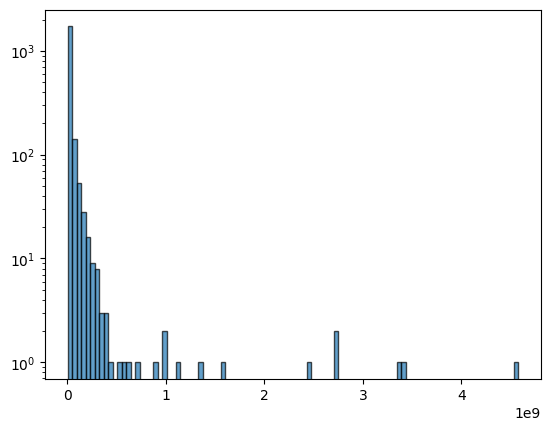

In [44]:
plt.hist(liq.head(N_NAMES)["adv"], alpha=0.7, edgecolor='black', bins=100, log=True)
plt.show()

In [45]:
# Take the top N most liquid names and persist the universe.
# (Swap head(N_NAMES) for a hard ADV threshold, e.g. .filter(pl.col("adv") > 1e6),
#  if you want a count that stays stable across rebuilds.)
universe = liq.head(N_NAMES)["symbol"].cast(pl.Utf8).to_list()

out_path = Path("../universe.txt")
out_path.write_text("\n".join(universe))
print(f"Wrote {len(universe)} symbols to {out_path.resolve()}")
universe[-20:]


Wrote 2000 symbols to /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/universe.txt


['ERII',
 'FWONA',
 'KFRC',
 'MDU',
 'TPH',
 'DGII',
 'AQN',
 'CGC',
 'DNB',
 'PSN',
 'WES',
 'ROAD',
 'PRAA',
 'LCII',
 'MOMO',
 'IGT',
 'VPL',
 'SCHA',
 'VONV',
 'KRUS']